# 02 · Exploratory and statistical analysis

This notebook uses the **training part only**. Validation and test blocks stay unseen, so nothing learned here can leak into model choice or the final score.

**It creates** the tables in `reports/tables/` (descriptive statistics, event means, absence shares, correlations, logistic coefficients, k-means cluster rates) and the figures `event_label_correlation.png`, `event_correlation_heatmap.png`, `logistic_event_coefficients.png`, `pca_scree_plot.png`, `pca_scatter.png`, `kmeans_elbow.png`.

In [1]:
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler

root = Path.cwd()
if not (root / 'datasets').exists():
    root = root.parent
raw = root / 'datasets' / 'hdfs_v1' / 'preprocessed'
processed = root / 'datasets' / 'processed'
figures = root / 'reports' / 'figures'
tables = root / 'reports' / 'tables'
tables.mkdir(parents=True, exist_ok=True)

NORMAL_COLOUR = '#8a8a8a'
ANOMALY_COLOUR = '#d4591c'
plt.rcParams.update({'axes.spines.top': False, 'axes.spines.right': False})

In [2]:
df = pd.read_csv(processed / 'hdfs_clean.csv')
splits = np.load(processed / 'splits.npz')
train = df.iloc[splits['train_idx']]
event_columns = [name for name in df.columns if name.startswith('E') and name[1:].isdigit()]
templates = pd.read_csv(raw / 'HDFS.log_templates.csv').set_index('EventId')['EventTemplate']

print(train.shape)
print(train['target'].value_counts())

(345036, 31)
target
0    334933
1     10103
Name: count, dtype: int64


## Descriptive statistics by class

Mean, median, standard deviation, minimum and maximum of each event count, for normal and anomalous training blocks.

In [3]:
normal = train.loc[train['target'] == 0, event_columns]
anomaly = train.loc[train['target'] == 1, event_columns]
normal_stats = normal.agg(['mean', 'median', 'std', 'min', 'max']).T
anomaly_stats = anomaly.agg(['mean', 'median', 'std', 'min', 'max']).T
display(normal_stats)
display(anomaly_stats)

,mean,median,std,min,max
E1,0.000000,0.0,0.000000,0.0,0.0
E2,0.208591,0.0,0.580566,0.0,4.0
E3,0.746296,0.0,2.504043,0.0,203.0
E4,0.622498,0.0,1.612059,0.0,41.0
E5,3.004789,3.0,0.101231,3.0,12.0
E6,0.004789,0.0,0.101231,0.0,9.0
E7,0.000000,0.0,0.000000,0.0,0.0
E8,0.000000,0.0,0.000000,0.0,0.0
E9,3.000000,3.0,0.000000,3.0,3.0
E10,0.000000,0.0,0.000000,0.0,0.0


,mean,median,std,min,max
E1,0.000990,0.0,0.044484,0.0,2.0
E2,0.184401,0.0,0.563654,0.0,4.0
E3,0.681679,0.0,3.283302,0.0,203.0
E4,0.491735,0.0,1.369878,0.0,15.0
E5,2.721073,3.0,1.106933,1.0,8.0
E6,0.262694,0.0,0.562014,0.0,5.0
E7,0.200831,0.0,0.417342,0.0,5.0
E8,0.002277,0.0,0.049695,0.0,2.0
E9,1.887162,3.0,1.448358,0.0,3.0
E10,0.004454,0.0,0.084891,0.0,3.0


In [4]:
# Save both classes in one tidy table: one row per event and class.
normal_stats['class'] = 'normal'
anomaly_stats['class'] = 'anomaly'
descriptive = pd.concat([normal_stats, anomaly_stats]).rename_axis('event').reset_index()
descriptive.to_csv(tables / 'training_descriptive_statistics.csv', index=False)

## Mean counts and how often each event is absent

`absent` is the share of blocks where the event never happened. Several events never appear in a normal training block, so even a single occurrence is suspicious.

In [5]:
means = pd.DataFrame(index=event_columns)
means['normal_mean'] = normal.mean()
means['anomaly_mean'] = anomaly.mean()
means['difference'] = means['anomaly_mean'] - means['normal_mean']
means['normal_absent'] = (normal == 0).mean()
means['anomaly_absent'] = (anomaly == 0).mean()
display(means.sort_values('difference', ascending=False))

,normal_mean,anomaly_mean,difference,normal_absent,anomaly_absent
E20,0.000379,0.321984,0.321604,0.999630,0.690884
E6,0.004789,0.262694,0.257905,0.996725,0.795407
E18,0.004661,0.262001,0.257341,0.996725,0.793824
E25,0.004661,0.262001,0.257341,0.996725,0.793824
E16,0.004661,0.258537,0.253876,0.996725,0.795407
E7,0.000000,0.200831,0.200831,1.000000,0.803821
E13,0.000000,0.082253,0.082253,1.000000,0.972582
E28,0.000030,0.074631,0.074601,0.999970,0.927546
E27,0.000006,0.055825,0.055819,0.999994,0.944175
E14,0.000000,0.006335,0.006335,1.000000,0.997229


In [6]:
means[['normal_mean', 'anomaly_mean', 'difference']].rename_axis('event').to_csv(tables / 'event_mean_counts.csv')
means[['normal_absent', 'anomaly_absent']].rename_axis('event').to_csv(tables / 'event_absence_share.csv')

never_in_normal = means.index[(means['normal_absent'] == 1) & (means['anomaly_absent'] < 1)]
print('events never seen in a normal training block but seen in anomalies:', list(never_in_normal))

events never seen in a normal training block but seen in anomalies: ['E1', 'E7', 'E8', 'E10', 'E12', 'E13', 'E14', 'E15', 'E17', 'E19', 'E24', 'E29']


## Correlation with the anomaly label

Pearson correlation between each event count and the 0/1 target. Events that never vary (always the same count) have no correlation and are dropped.

In [7]:
varying_events = [name for name in event_columns if train[name].std() > 0]
constant_events = [name for name in event_columns if name not in varying_events]
print('constant in training data:', constant_events)

corr = train[varying_events + ['target']].corr()['target'].drop('target').sort_values()
corr_table = pd.DataFrame({'correlation_with_anomaly': corr, 'template': templates[corr.index]})
corr_table.rename_axis('event').sort_values('correlation_with_anomaly', key=abs, ascending=False).to_csv(
    tables / 'event_correlations.csv')

constant in training data: ['E22']


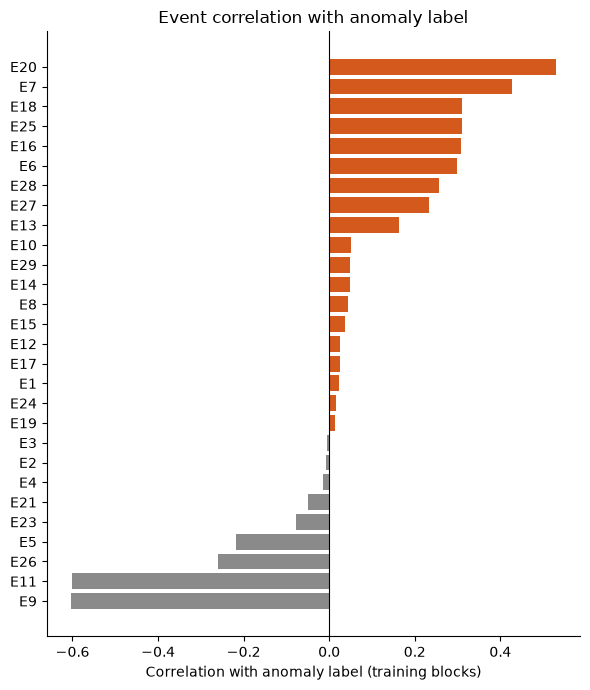

In [8]:
fig, ax = plt.subplots(figsize=(6, 7))
colours = [ANOMALY_COLOUR if value > 0 else NORMAL_COLOUR for value in corr.values]
ax.barh(corr.index, corr.values, color=colours)
ax.axvline(0, color='black', linewidth=0.8)
ax.set_xlabel('Correlation with anomaly label (training blocks)')
ax.set_title('Event correlation with anomaly label')
fig.tight_layout()
fig.savefig(figures / 'event_label_correlation.png', dpi=160)
plt.show()

The template text explains what the strongest events are.

In [9]:
top_events = corr.abs().sort_values(ascending=False).head(6).index
display(corr_table.loc[top_events])

,correlation_with_anomaly,template
E9,-0.603591,[*]Received block[*]of size[*]from[*]
E11,-0.600151,[*]PacketResponder[*]for block[*]terminating[*]
E20,0.529574,[*]Unexpected error trying to delete block[*]B...
E7,0.428423,[*]writeBlock[*]received exception[*]
E25,0.309808,[*]BLOCK* ask[*]to replicate[*]to[*]
E18,0.309808,[*]Starting thread to transfer block[*]to[*]


## Correlation between events

Some events always happen together (for example, one event per replica). Strongly correlated features carry the same information, which matters for logistic regression coefficients below.

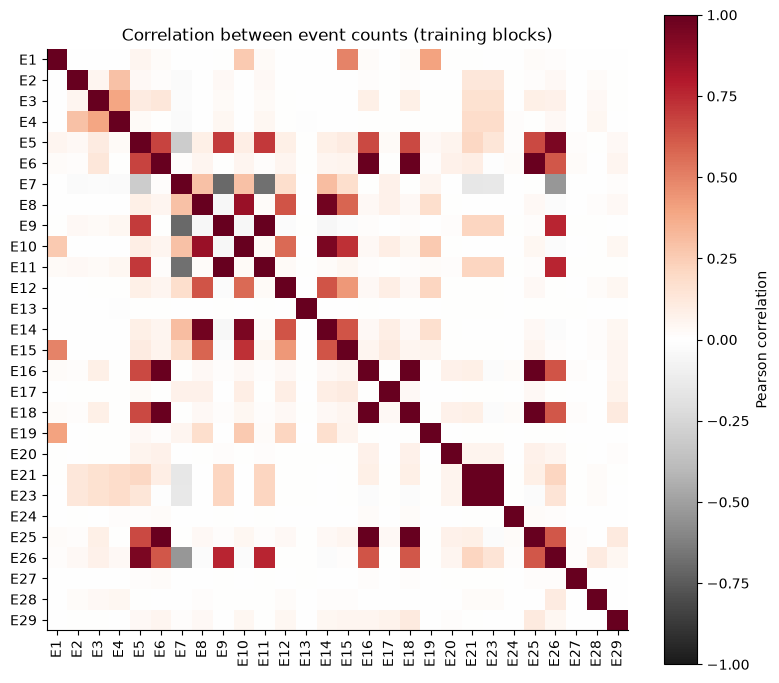

In [10]:
event_corr = train[varying_events].corr()

fig, ax = plt.subplots(figsize=(8, 7))
image = ax.imshow(event_corr.values, cmap='RdGy_r', vmin=-1, vmax=1)
ax.set_xticks(range(len(varying_events)), varying_events, rotation=90)
ax.set_yticks(range(len(varying_events)), varying_events)
fig.colorbar(image, ax=ax, label='Pearson correlation')
ax.set_title('Correlation between event counts (training blocks)')
fig.tight_layout()
fig.savefig(figures / 'event_correlation_heatmap.png', dpi=160)
plt.show()

In [11]:
# List the pairs that move almost perfectly together.
pairs = []
for i, first in enumerate(varying_events):
    for second in varying_events[i + 1:]:
        if abs(event_corr.loc[first, second]) > 0.95:
            pairs.append((first, second, round(event_corr.loc[first, second], 4)))
print(pairs)

[('E6', 'E16', np.float64(0.9881)), ('E6', 'E18', np.float64(0.9853)), ('E6', 'E25', np.float64(0.9853)), ('E8', 'E14', np.float64(0.9664)), ('E9', 'E11', np.float64(0.9971)), ('E16', 'E18', np.float64(0.9973)), ('E16', 'E25', np.float64(0.9973)), ('E18', 'E25', np.float64(1.0)), ('E21', 'E23', np.float64(0.9938))]


## Logistic regression coefficients

Counts are standardised first, so coefficients are comparable. A positive coefficient raises the anomaly score when the other counts are held fixed.
Because some events are almost perfectly correlated (above), individual coefficients can split or swap sign between twin events; read them as a ranking, not as causes.

In [12]:
scaler = StandardScaler()
X_train = scaler.fit_transform(train[event_columns])
y_train = train['target']

logistic = LogisticRegression(class_weight='balanced', max_iter=1000, random_state=42)
logistic.fit(X_train, y_train)

coef = pd.DataFrame({'event': event_columns, 'coefficient': logistic.coef_[0]})
coef['absolute_coefficient'] = coef['coefficient'].abs()
coef['template'] = templates[coef['event']].values
coef = coef.sort_values('absolute_coefficient', ascending=False)
coef.to_csv(tables / 'logistic_event_coefficients.csv', index=False)
display(coef)

,event,coefficient,absolute_coefficient,template
20,E21,12.044615,12.044615,[*]Deleting block[*]file[*]
15,E16,-5.318854,5.318854,[*]:Transmitted block[*]to[*]
22,E23,-3.616260,3.616260,[*]BLOCK* NameSystem[*]delete:[*]is added to i...
17,E18,2.615310,2.615310,[*]Starting thread to transfer block[*]to[*]
24,E25,2.615310,2.615310,[*]BLOCK* ask[*]to replicate[*]to[*]
25,E26,-1.732779,1.732779,[*]BLOCK* NameSystem[*]addStoredBlock: blockMa...
8,E9,-1.620993,1.620993,[*]Received block[*]of size[*]from[*]
10,E11,-1.611755,1.611755,[*]PacketResponder[*]for block[*]terminating[*]
26,E27,1.504630,1.504630,[*]BLOCK* NameSystem[*]addStoredBlock: Redunda...
5,E6,1.433840,1.433840,[*]Received block[*]src:[*]dest:[*]of size[*]


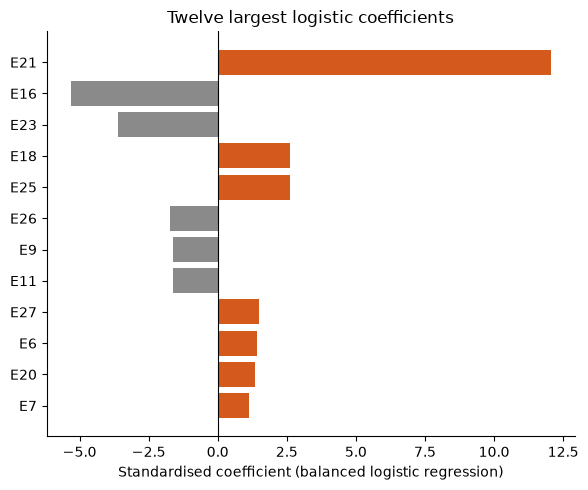

In [13]:
top_coef = coef.head(12).iloc[::-1]
fig, ax = plt.subplots(figsize=(6, 5))
colours = [ANOMALY_COLOUR if value > 0 else NORMAL_COLOUR for value in top_coef['coefficient']]
ax.barh(top_coef['event'], top_coef['coefficient'], color=colours)
ax.axvline(0, color='black', linewidth=0.8)
ax.set_xlabel('Standardised coefficient (balanced logistic regression)')
ax.set_title('Twelve largest logistic coefficients')
fig.tight_layout()
fig.savefig(figures / 'logistic_event_coefficients.png', dpi=160)
plt.show()

## PCA

PCA finds the directions along which event counts vary most. The scree plot shows how much variance each component explains; the scatter shows a fixed random sample of training blocks on the first two components.

components needed for 95% of the variance: 16


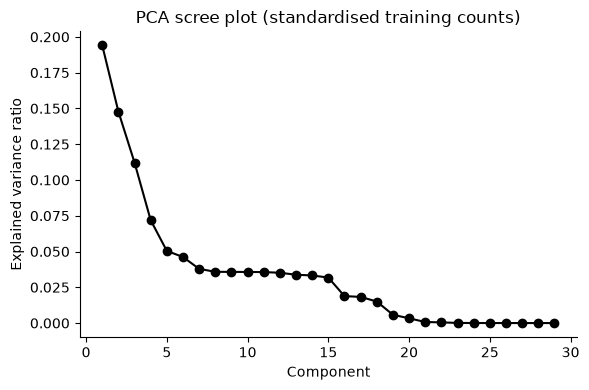

In [14]:
pca = PCA(random_state=42)
components = pca.fit_transform(X_train)
cumulative = np.cumsum(pca.explained_variance_ratio_)
print('components needed for 95% of the variance:', np.argmax(cumulative >= 0.95) + 1)

fig, ax = plt.subplots(figsize=(6, 4))
ax.plot(range(1, len(cumulative) + 1), pca.explained_variance_ratio_, marker='o', color='black')
ax.set_xlabel('Component')
ax.set_ylabel('Explained variance ratio')
ax.set_title('PCA scree plot (standardised training counts)')
fig.tight_layout()
fig.savefig(figures / 'pca_scree_plot.png', dpi=160)
plt.show()

In [15]:
# Saved for the website's scree chart.
pca_table = pd.DataFrame({'component': range(1, len(cumulative) + 1),
                          'explained_variance_ratio': pca.explained_variance_ratio_,
                          'cumulative': cumulative})
pca_table.to_csv(tables / 'pca_explained_variance.csv', index=False)

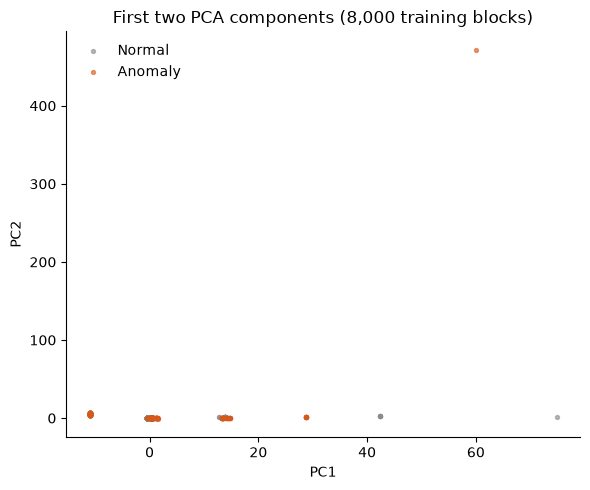

In [16]:
# A fixed sample keeps the scatter readable; anomalies are drawn last so they are not hidden.
rng = np.random.default_rng(42)
sample = rng.choice(len(components), size=8000, replace=False)
sample_target = y_train.values[sample]

fig, ax = plt.subplots(figsize=(6, 5))
for value, colour, name in [(0, NORMAL_COLOUR, 'Normal'), (1, ANOMALY_COLOUR, 'Anomaly')]:
    points = components[sample][sample_target == value]
    ax.scatter(points[:, 0], points[:, 1], s=8, alpha=0.6, color=colour, label=name)
ax.set_xlabel('PC1')
ax.set_ylabel('PC2')
ax.set_title('First two PCA components (8,000 training blocks)')
ax.legend(frameon=False)
fig.tight_layout()
fig.savefig(figures / 'pca_scatter.png', dpi=160)
plt.show()

## k-means on normal behaviour

k-means is fitted to a fixed random sample of 30,000 **normal** training blocks. The elbow plot (inertia against k) is used to pick k. Every training block is then assigned to its nearest cluster, and the anomaly rate per cluster shows whether anomalies gather in unusual groups.

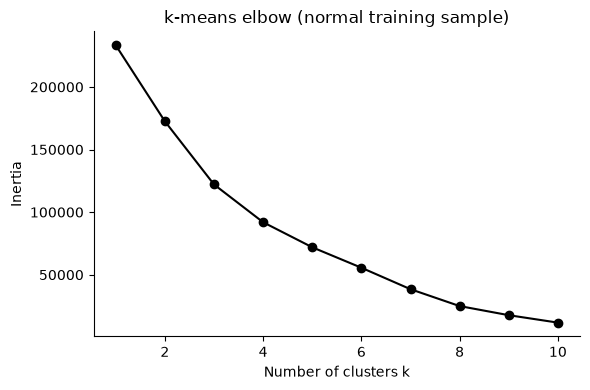

In [17]:
normal_X = scaler.transform(normal)
normal_sample = normal_X[rng.choice(len(normal_X), size=30000, replace=False)]

inertias = []
k_values = range(1, 11)
for k in k_values:
    model = KMeans(n_clusters=k, random_state=42, n_init=10)
    model.fit(normal_sample)
    inertias.append(model.inertia_)

fig, ax = plt.subplots(figsize=(6, 4))
ax.plot(list(k_values), inertias, marker='o', color='black')
ax.set_xlabel('Number of clusters k')
ax.set_ylabel('Inertia')
ax.set_title('k-means elbow (normal training sample)')
fig.tight_layout()
fig.savefig(figures / 'kmeans_elbow.png', dpi=160)
plt.show()

In [18]:
# Saved for the website's elbow chart.
pd.DataFrame({'k': list(k_values), 'inertia': inertias}).to_csv(tables / 'kmeans_elbow.csv', index=False)

In [19]:
kmeans = KMeans(n_clusters=4, random_state=42, n_init=10)
kmeans.fit(normal_sample)
clusters = kmeans.predict(X_train)

cluster_table = pd.DataFrame({'cluster': clusters, 'target': y_train.values})
cluster_rates = cluster_table.groupby('cluster')['target'].agg(blocks='size', anomaly_rate='mean').reset_index()
cluster_rates.to_csv(tables / 'kmeans_cluster_anomaly_rates.csv', index=False)
display(cluster_rates)

,cluster,blocks,anomaly_rate
0,0,215772,0.020341
1,1,758,0.701847
2,2,65914,0.059183
3,3,62592,0.020466


## Summary

- Some events never occur in normal training blocks, and the strongest label correlations come from a small group of events; their templates are printed above.
- Several events are near-perfect twins, so single coefficients should not be over-read.
- One small k-means cluster of unusual blocks has a much higher anomaly rate than the others (table above), which supports the PCA detector idea in notebook 03: learn "normal", then flag what does not fit.